In [250]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [251]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.load_master_data import load_master_data

df = load_master_data()

df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 39 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   season                             25939 non-null  int64         
 1   round                              25939 non-null  int64         
 2   driver_id                          25939 non-null  category      
 3   driver_name                        25939 non-null  category      
 4   constructor_id                     25939 non-null  category      
 5   grid                               25939 non-null  int64         
 6   position                           25939 non-null  int64         
 7   points                             25939 non-null  float64       
 8   laps                               25939 non-null  int64         
 9   status                             25939 non-null  category      
 10  time                               8354 non-n

In [252]:
target = "podium"

df[target].value_counts()

df[target].value_counts(normalize=True)

podium
0    0.865916
1    0.134084
Name: proportion, dtype: float64

In [253]:
features = [
    "grid",
    "qualifying_position",
    "driver_age",
    "pole_position",
    "front_row",
    "constructor_name",
    "driver_nationality",
    "circuit_country",
    "current_season_points",
    "avg_points_per_season",
    "constructor_points_current_season",
    "points_last_5_races"
]

descriminative_numerical_features = []
descriminative_categorical_features = []

In [254]:
X = df[features]

y = df[target]

In [255]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   grid                               25939 non-null  int64   
 1   qualifying_position                11029 non-null  float64 
 2   driver_age                         25939 non-null  float64 
 3   pole_position                      25939 non-null  int64   
 4   front_row                          25939 non-null  int64   
 5   constructor_name                   25939 non-null  category
 6   driver_nationality                 25939 non-null  category
 7   circuit_country                    25939 non-null  category
 8   current_season_points              25939 non-null  float64 
 9   avg_points_per_season              22289 non-null  float64 
 10  constructor_points_current_season  25939 non-null  float64 
 11  points_last_5_races                25121 non-null  f

## GRID T TEST

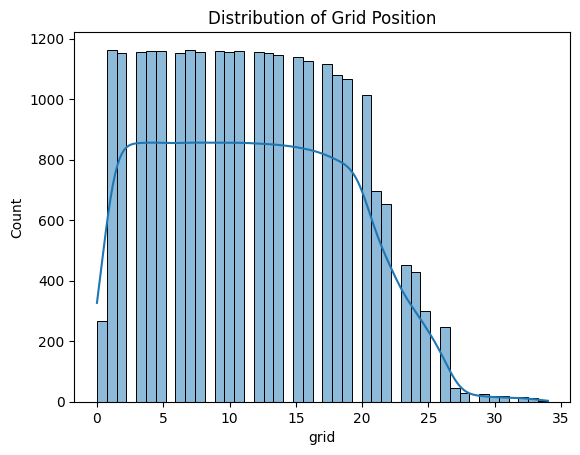

In [256]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["grid"], kde=True)

plt.title("Distribution of Grid Position")

plt.show()

In [257]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["grid"]

non_podium_group = df[
    df["podium"] == 0
]["grid"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 9878160.5
P-value: 0.0


In [258]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'grid' is discriminative.")
    descriminative_numerical_features.append("grid")
else:
    print("Fail to reject H0")
    print("The variable 'grid' is class independent.")

Reject H0
The variable 'grid' is discriminative.


### Hypothesis Test for Grid Position

H0: The variable 'grid' is class independent.

H1: The variable 'grid' is not class independent.

Confidence level = 95%
α = 0.05

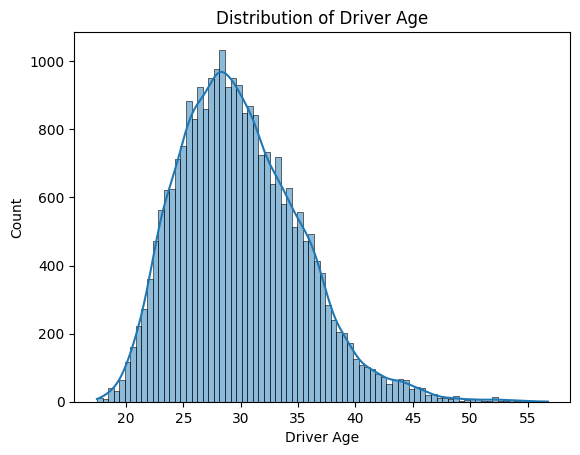

In [259]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    df["driver_age"],
    kde=True
)

plt.title("Distribution of Driver Age")

plt.xlabel("Driver Age")

plt.ylabel("Count")

plt.show()

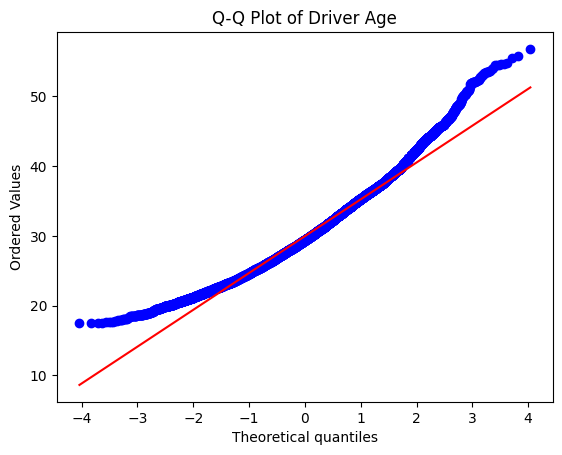

In [260]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(
    df["driver_age"].dropna(),
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Driver Age")

plt.show()

In [261]:
from scipy.stats import mannwhitneyu


# Separate groups
podium_group = df[
    df["podium"] == 1
]["driver_age"]

non_podium_group = df[
    df["podium"] == 0
]["driver_age"]

# T-test
t_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    nan_policy="omit"
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 42559063.5
P-value: 1.656553146433306e-17


In [262]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'driver_age' is discriminative.")
    descriminative_numerical_features.append("driver_age")
else:
    print("Fail to reject H0")
    print("The variable 'driver_age' is class independent.")

Reject H0
The variable 'driver_age' is discriminative.


In [263]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["front_row"],
    df["podium"]
)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 4045.2462825884727
P-value: 0.0


In [264]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Front row starts are associated with podium finishes.")
    descriminative_categorical_features.append("front_row")
else:
    print("Fail to reject H0")
    print("Front row starts are independent of podium finishes.")

Reject H0
Front row starts are associated with podium finishes.


In [265]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    df["constructor_name"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 3711.3602882742834
P-value: 0.0


In [266]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor name is associated with podium finishes.")
    descriminative_categorical_features.append("constructor_name")
else:
    print("Fail to reject H0")
    print("Constructor name is independent of podium finishes.")

Reject H0
Constructor name is associated with podium finishes.


In [267]:
# Contingency table
contingency_table = pd.crosstab(
    df["circuit_country"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

df.info()

Chi-square statistic: 9.27955285158374
P-value: 0.999984847062557
<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 39 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   season                             25939 non-null  int64         
 1   round                              25939 non-null  int64         
 2   driver_id                          25939 non-null  category      
 3   driver_name                        25939 non-null  category      
 4   constructor_id                     25939 non-null  category      
 5   grid                               25939 non-null  int64         
 6   position                           25939 non-null  int64         
 7   points                             25939 non-null  float64       
 8   laps                               25939 non-null  int64         
 9   status                             25939 non-null 

In [268]:
# Contingency table
contingency_table = pd.crosstab(
    df["driver_nationality"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 795.4696292875008
P-value: 8.634066317202463e-142


In [269]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Driver nationality is associated with podium finishes.")
    descriminative_categorical_features.append("driver_nationality")
else:
    print("Fail to reject H0")
    print("Driver nationality is independent of podium finishes.")

Reject H0
Driver nationality is associated with podium finishes.


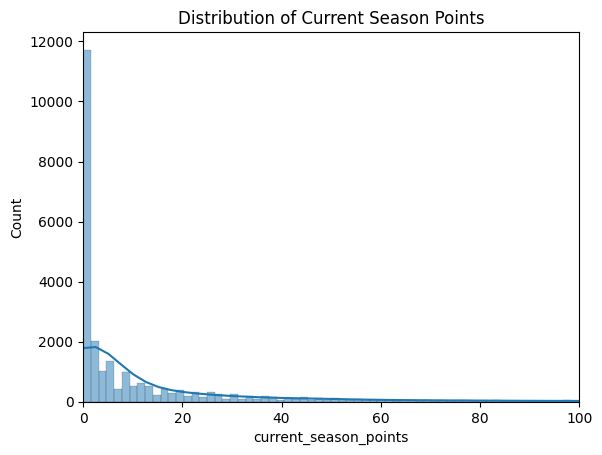

In [270]:
sns.histplot(
    df["current_season_points"],
    kde=True
)

plt.title("Distribution of Current Season Points")

plt.xlim(0,100)

plt.show()

In [271]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["current_season_points"]

non_podium_group = df[
    df["podium"] == 0
]["current_season_points"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Current season points is discriminative.")
    descriminative_numerical_features.append("current_season_points")
else:
    print("Fail to reject H0")
    print("Current season points is class independent.")

U-statistic: 58953609.0
P-value: 0.0
Reject H0
Current season points is discriminative.


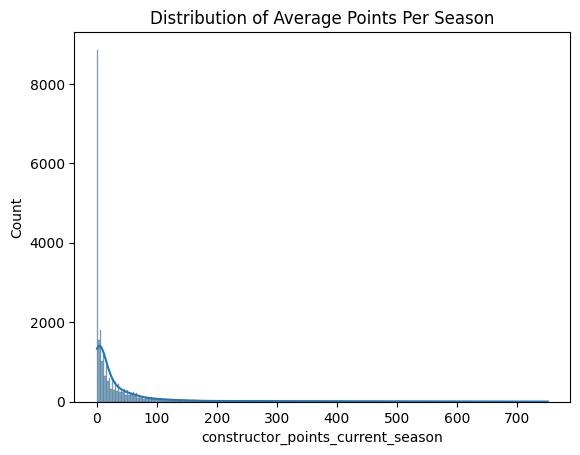

In [272]:
sns.histplot(
    df["constructor_points_current_season"],
    kde=True
)

plt.title("Distribution of Average Points Per Season")

plt.show()



In [273]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["constructor_points_current_season"].dropna()

non_podium_group = df[
    df["podium"] == 0
]["constructor_points_current_season"].dropna()

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 58249338.5
P-value: 0.0


In [274]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor points is discriminative.")
    descriminative_numerical_features.append("constructor_points_current_season")
else:
    print("Fail to reject H0")
    print("Constructor points is class independent.")

Reject H0
Constructor points is discriminative.


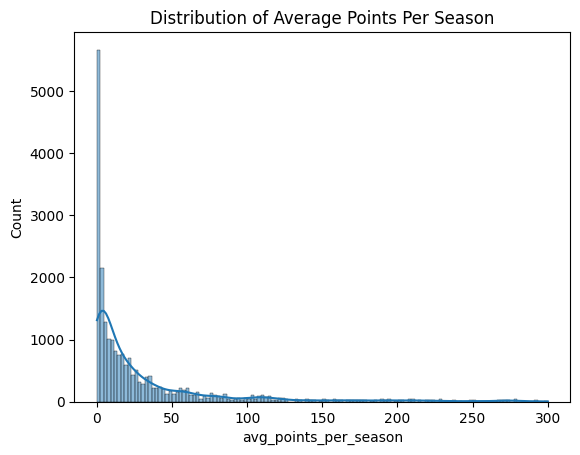

In [275]:
sns.histplot(
    df["avg_points_per_season"],
    kde=True
)

plt.title("Distribution of Average Points Per Season")

plt.show()

In [276]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["avg_points_per_season"].dropna()

non_podium_group = df[
    df["podium"] == 0
]["avg_points_per_season"].dropna()

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 45537100.0
P-value: 0.0


In [277]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Average points per season is discriminative.")
    descriminative_numerical_features.append("avg_points_per_season")
else:
    print("Fail to reject H0")
    print("Average points per season is class independent.")

Reject H0
Average points per season is discriminative.


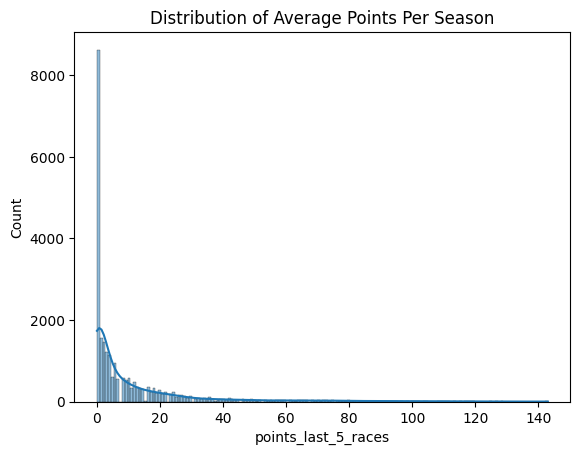

In [278]:
sns.histplot(
    df["points_last_5_races"],
    kde=True
)

plt.title("Distribution of Average Points Per Season")

plt.show()

In [279]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["points_last_5_races"].dropna()

non_podium_group = df[
    df["podium"] == 0
]["points_last_5_races"].dropna()

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 60882864.5
P-value: 0.0


In [280]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("points_last_5_races is discriminative.")
    descriminative_numerical_features.append("points_last_5_races")

else:
    print("Fail to reject H0")
    print("points_last_5_races is class independent.")

Reject H0
points_last_5_races is discriminative.


In [281]:
correlation_matrix = (
    df[descriminative_numerical_features]
    .corr()
)

correlation_matrix

,grid,driver_age,current_season_points,constructor_points_current_season,avg_points_per_season,points_last_5_races
grid,1.000000,-0.057301,-0.350153,-0.342130,-0.309308,-0.460435
driver_age,-0.057301,1.000000,-0.029959,-0.015882,0.051435,-0.014406
current_season_points,-0.350153,-0.029959,1.000000,0.954218,0.631626,0.784353
constructor_points_current_season,-0.342130,-0.015882,0.954218,1.000000,0.590437,0.735334
avg_points_per_season,-0.309308,0.051435,0.631626,0.590437,1.000000,0.729107
points_last_5_races,-0.460435,-0.014406,0.784353,0.735334,0.729107,1.000000


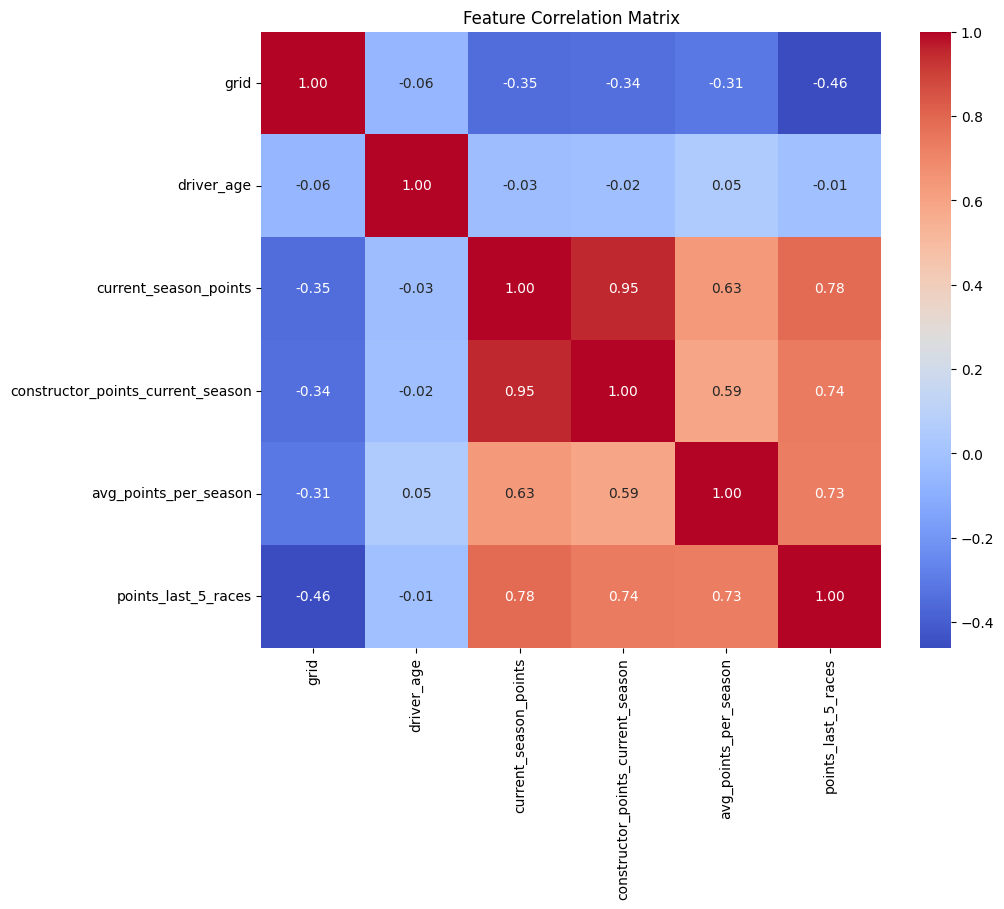

In [282]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [283]:
corr_matrix = (
    df[descriminative_numerical_features]
    .corr()
    .abs()
)

# Upper triangle only
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

# Find features with correlation > 0.9
high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.9)
]

print(high_corr_features)

['constructor_points_current_season']


In [284]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):

    contingency_table = pd.crosstab(x, y)

    chi2 = chi2_contingency(contingency_table)[0]

    n = contingency_table.sum().sum()

    r, k = contingency_table.shape

    return np.sqrt(
        chi2 / (n * (min(r, k) - 1))
    )

In [285]:
cramers_matrix = pd.DataFrame(
    index=descriminative_categorical_features,
    columns=descriminative_categorical_features
)

for col1 in descriminative_categorical_features:
    for col2 in descriminative_categorical_features:

        cramers_matrix.loc[col1, col2] = (
            cramers_v(
                df[col1],
                df[col2]
            )
        )

cramers_matrix

,front_row,constructor_name,driver_nationality
front_row,0.999785,0.323896,0.157325
constructor_name,0.323896,1.0,0.369019
driver_nationality,0.157325,0.369019,1.0


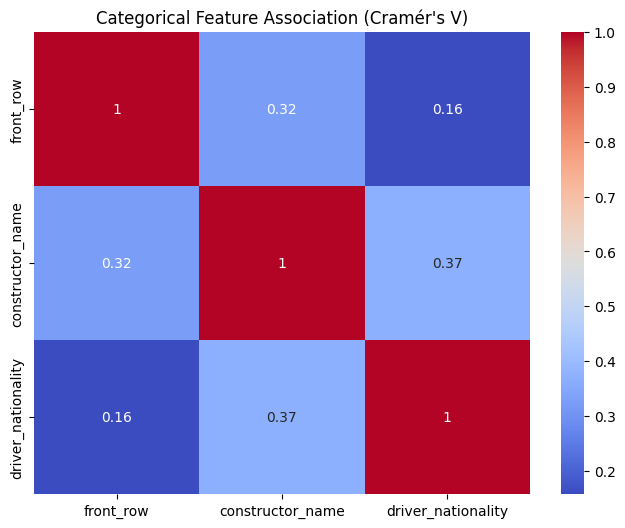

In [286]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cramers_matrix.astype(float),
    annot=True,
    cmap="coolwarm"
)

plt.title("Categorical Feature Association (Cramér's V)")

plt.show()